# Learning rate and optimisers

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/1_foundations/02_learning_rate_and_optimisers.ipynb) &nbsp; Guide note: [guide-foundations](https://www.matthewwnuk.com/guide-foundations.html#lr)

The learning rate is the most important number in training. This notebook sweeps it for two optimisers,
plots the usual warmup-and-cosine schedule, and compares three optimisers on the same problem.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits(); X, y = torch.tensor(X), torch.tensor(y)
idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(0)); tr, va = idx[:1300], idx[1300:]

def mlp(): return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 10))

def train(make_opt, epochs, seed=0):
    torch.manual_seed(seed); m = mlp(); opt = make_opt(m.parameters()); curve = []
    for ep in range(epochs):
        perm = tr[torch.randperm(len(tr))]
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): curve.append(F.cross_entropy(m(X[va]), y[va]).item())
    return curve

/home/mwnuk/work/robot-learning-notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The sweep

Train the same network at thirteen learning rates, half a decade apart. Each optimiser has a basin.
Too low and the loss never leaves ln(10), the loss of guessing. Too high and training diverges.

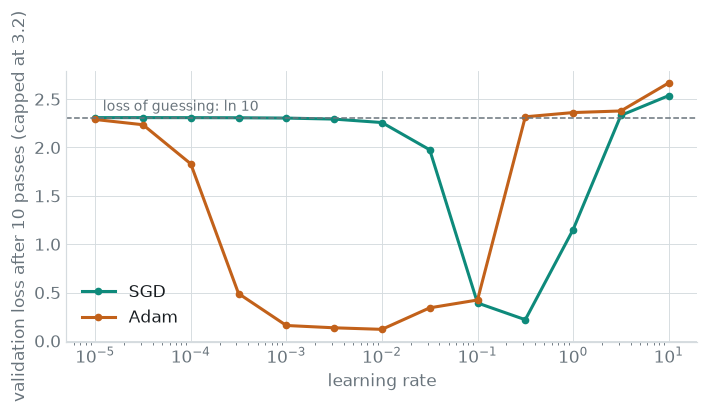

SGD: best rate 3e-01, loss 0.219
Adam: best rate 1e-02, loss 0.120


In [3]:
lrs = [10 ** e for e in np.arange(-5, 1.01, 0.5)]
def final_loss(cls, lr, seed):
    v = train(lambda p: cls(p, lr), 10, seed)[-1]
    return v if math.isfinite(v) and v < 3.2 else 3.2          # diverged runs are capped so they fit on the plot
sweep = {name: [np.mean([final_loss(cls, lr, s) for s in range(2)]) for lr in lrs] for name, cls in (("SGD", torch.optim.SGD), ("Adam", torch.optim.Adam))}
plt.figure(figsize=(7.4, 3.2))
for name, v in sweep.items(): plt.plot(lrs, v, marker="o", ms=4, label=name)
plt.axhline(math.log(10), color=style.MUTED, ls="--", lw=1); plt.text(1.2e-5, 2.38, "loss of guessing: ln 10", color=style.MUTED, fontsize=9)
plt.xscale("log"); plt.xlabel("learning rate"); plt.ylabel("validation loss after 10 passes (capped at 3.2)"); plt.legend(); plt.show()
for name, v in sweep.items(): print(f"{name}: best rate {lrs[int(np.argmin(v))]:.0e}, loss {min(v):.3f}")

Two things to notice. The usable range is one to two orders of magnitude wide, so a coarse sweep on a
log scale finds it. And the two optimisers want very different rates, which is why a learning rate
copied from another project rarely transfers.

## The schedule

In practice the rate ramps up from zero, because early gradients are large and noisy, and then decays
along a cosine.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


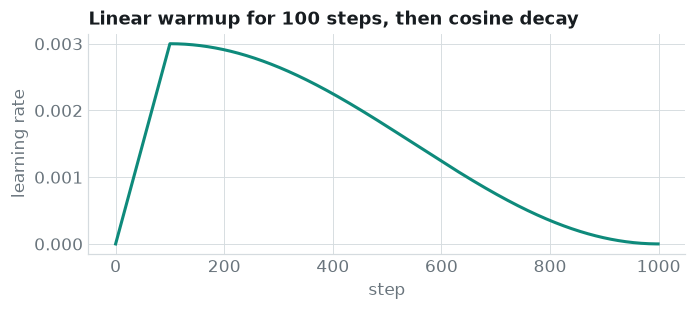

In [4]:
def schedule(t, total, warmup, peak):
    return peak * t / warmup if t < warmup else 0.5 * peak * (1 + math.cos(math.pi * (t - warmup) / (total - warmup)))
T = 1000; plt.figure(figsize=(7, 2.6)); plt.plot([schedule(t, T, 100, 3e-3) for t in range(T)])
plt.xlabel("step"); plt.ylabel("learning rate"); plt.title("Linear warmup for 100 steps, then cosine decay"); plt.show()

## Three optimisers

Plain gradient descent, gradient descent with momentum, and AdamW, each at a reasonable rate.

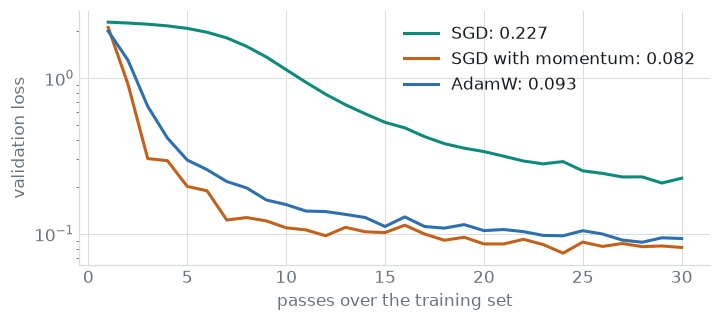

In [5]:
opts = {"SGD": lambda p: torch.optim.SGD(p, 0.05), "SGD with momentum": lambda p: torch.optim.SGD(p, 0.05, momentum=0.9),
        "AdamW": lambda p: torch.optim.AdamW(p, 1e-3, weight_decay=0.01)}
plt.figure(figsize=(7.4, 3))
for name, mk in opts.items():
    c = train(mk, 30); plt.plot(range(1, 31), c, label=f"{name}: {c[-1]:.3f}")
plt.yscale("log"); plt.xlabel("passes over the training set"); plt.ylabel("validation loss"); plt.legend(); plt.show()

## Adam by hand

Adam keeps a running average of the gradient (`m`) and of its square (`v`), and divides one by the root
of the other. The cell below implements it in a few lines and checks it against PyTorch's.

In [6]:
torch.manual_seed(0); w = torch.randn(5, requires_grad=True); w2 = w.detach().clone().requires_grad_(True)
target = torch.arange(5.0); opt = torch.optim.Adam([w2], lr=0.1); m = torch.zeros(5); v = torch.zeros(5); b1, b2, eps = 0.9, 0.999, 1e-8
for t in range(1, 51):
    g = torch.autograd.grad(((w - target) ** 2).sum(), w)[0]
    m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
    with torch.no_grad(): w -= 0.1 * (m / (1 - b1 ** t)) / ((v / (1 - b2 ** t)).sqrt() + eps)
    loss = ((w2 - target) ** 2).sum(); opt.zero_grad(); loss.backward(); opt.step()
print("largest difference from torch.optim.Adam after 50 steps:", (w - w2).abs().max().item())

largest difference from torch.optim.Adam after 50 steps: 7.152557373046875e-07


## Things to try

- Add `weight_decay=0.1` to AdamW and see what happens to the validation loss.
- Remove the warmup from the schedule and train a deeper network with a high peak rate.
- Sweep the batch size at a fixed learning rate. Which direction makes training less stable?